# Phase 7: Orchestration and monitoring

**Goal:** run the whole pipeline by itself every shift, record its health, and raise a retraining flag when the data or the model's errors say so.

> The forecasts are real model outputs; the plant clock and the failure log are simulated from NASA's data (see `docs/MONITORING.md`).

## Concepts in plain words

- **Orchestration:** running steps in order, on a schedule, with retries and logs. In Prefect a *task* is one step, a *flow* is the sequence, a *deployment* runs it on a schedule.
- **Idempotent:** running the same shift twice leaves the same rows.
- **Label timing:** a prediction can only be scored once the engine has actually failed.
- **Data drift:** incoming readings stop looking like the training data. The **KS test** measures the biggest gap between two distributions; **Holm** corrects for testing 14 sensors at once.
- **Retraining flag:** a pre-set rule that says the model should be retrained.

In [1]:
import json, sys
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
FIG = ROOT / 'docs' / 'figures'
rule = json.loads((ROOT / 'pipeline/monitoring_rule.json').read_text())
chk = json.loads((ROOT / 'results/phase7/phase7_checks.json').read_text())
res = json.loads((ROOT / 'results/phase7/results_phase7.json').read_text())
health = pd.read_csv(ROOT / 'results/phase7/phase7_health.csv')
drift = pd.read_csv(ROOT / 'results/phase7/phase7_drift.csv')
print({k: res[k] for k in ('shifts', 'runs', 'forecasts', 'invalid_forecasts', 'work_orders')})

{'shifts': 484, 'runs': 968, 'forecasts': 29692, 'invalid_forecasts': 0, 'work_orders': 198}


## 7.1 The rule, fixed before the test replay

In [2]:
pd.DataFrame({'alpha': [rule['drift']['alpha']], 'drift false alarms (validation)': [rule['drift']['false_alarm_chosen']],
              'RMSE multiplier': [rule['health']['rmse_multiplier']], 'miss-rate limit': [rule['health']['miss_rate_limit']],
              'combined false-alarm estimate': [rule['combined_false_alarm_upper_estimate']]})

,alpha,drift false alarms (validation),RMSE multiplier,miss-rate limit,combined false-alarm estimate
0,0.01,0.002755,1.45,0.2,0.025174


## 7.2 Model health over the replay

Rolling metrics of the 20 most recently labelled engines, with the pre-set limits.

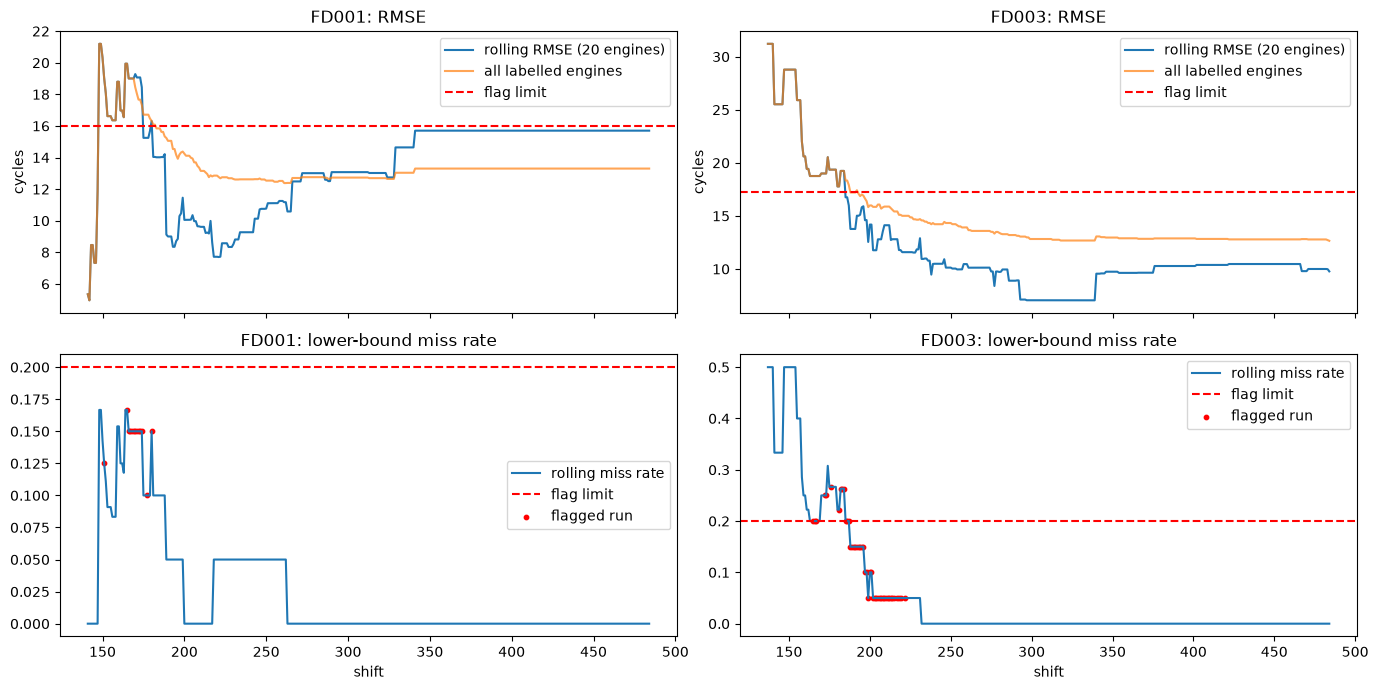

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(14, 7), sharex='col')
for j, ds in enumerate(['FD001', 'FD003']):
    h = health[health.dataset == ds]
    ref = rule['health']['reference'][ds]['reference_rmse']
    axes[0, j].plot(h['shift'], h.rmse, label='rolling RMSE (20 engines)')
    axes[0, j].plot(h['shift'], h.cum_rmse, label='all labelled engines', alpha=0.7)
    axes[0, j].axhline(rule['health']['rmse_multiplier'] * ref, color='red', ls='--', label='flag limit')
    axes[0, j].set(title=f'{ds}: RMSE', ylabel='cycles'); axes[0, j].legend()
    axes[1, j].plot(h['shift'], h.lower_bound_miss_rate, label='rolling miss rate')
    axes[1, j].axhline(rule['health']['miss_rate_limit'], color='red', ls='--', label='flag limit')
    fl = h[h.needs_retraining]
    axes[1, j].scatter(fl['shift'], fl.lower_bound_miss_rate, color='red', s=10, label='flagged run')
    axes[1, j].set(title=f'{ds}: lower-bound miss rate', xlabel='shift'); axes[1, j].legend()
fig.tight_layout(); fig.savefig(FIG / 'phase7_health.png', dpi=150, bbox_inches='tight')

## 7.3 Drift on the clean test replay

In [4]:
t = drift[drift.tested]
runs = t.groupby(['dataset', 'shift']).drifted.any().reset_index()
print('runs with a drifted sensor:', int(runs.drifted.sum()), 'of', len(runs))
t[t.drifted][['dataset', 'shift', 'sensor', 'n_recent', 'ks_stat', 'p_holm']]

runs with a drifted sensor: 51 of 438


,dataset,shift,sensor,n_recent,ks_stat,p_holm
1867,FD001,134,s17,54,0.384435,0.001281
1895,FD001,136,s17,50,0.368861,0.003814
2110,FD001,151,s4,37,0.398198,0.006084
2305,FD001,165,s3,26,0.469457,0.003243
2315,FD001,166,s17,26,0.447761,0.007571
...,...,...,...,...,...,...
9812,FD003,217,s8,23,0.521739,0.003267
9824,FD003,218,s4,23,0.501976,0.007095
9838,FD003,219,s4,23,0.547431,0.001339
9840,FD003,219,s8,23,0.503953,0.006152


## 7.4 The guide's checks

In [5]:
chk['flow_check']

{'dataset': 'FD001',
 'sensor': 's4',
 'clean_runs': 18,
 'clean_runs_flagged': 0,
 'clean_runs_drifted': 0,
 'plus5pct': {'quarantined': 100,
  'readings': 100,
  'drifted': ['s4'],
  'needs_retraining': True,
  'other_dataset_flagged': False},
 'plus1sd': {'quarantined': 0,
  'readings': 100,
  'drifted': ['s4'],
  'needs_retraining': True}}

In [6]:
pd.DataFrame({k: {'mean': v['mean'], 'weakest': f"{v['weakest_sensor']} {v['min']:.0%}"} for k, v in chk['test_window_power'].items()}).T

,mean,weakest
newest shift: +1%,0.794218,s4 38%
newest shift: +2%,0.955782,s4 76%
newest shift: +5%,1.0,s2 100%
newest shift: +0.5 sd,0.035714,s2 0%
newest shift: +1 sd,0.267007,s2 2%


## What the results say

1. **The flow ran every shift.** 968 runs (484 shifts x 2 datasets), all complete, 29,692 forecasts (0 invalid). Re-running, retrying and resuming are proven in `tests/test_flow.py`.
2. **Monitoring is tied to the published results.** Once all 100 engines of a dataset are labelled, the flow's RMSE equals the published test RMSE (FD001 13.30, FD003 12.66).
3. **The guide's drift check passes.** +5% on s4: the validator quarantined all 100 readings, drift still flagged s4, and the retraining flag was set; the 18 clean runs before it set nothing.
4. **False alarms on clean test data:** 11.64% of runs had a drifted sensor (51 of 438), against 0.28% on clean validation streams when the rule was chosen. That is ABOVE the 5% target: reported, not re-tuned.
5. **Retraining flags on the clean test replay:** FD001 15 runs, FD003 45 runs; 10 come from the health rules (labelled engines) and 51 from drift. None of these is a deliberate fault: they show what the pre-registered rule does on real test data, and the limits were not moved after seeing them.
6. **Why the clean runs were flagged (traced, not tuned):** the drift reference matches age but not wear. Test engines still reporting late are healthier than training engines of the same age (FD003 flagged windows: median remaining life 104 vs 66), and every sensor that 'drifted' is one of the 7 most wear-related sensors. The first labels come from the shortest-lived engines (FD001 first 20: RMSE 19.0 vs 11.4 for the rest), which is what tripped the RMSE rule. A fix must be chosen on validation and confirmed on fresh data (FD002/FD004).

## Why we did these tasks

| # | Task | Why we did it | What we learned | What it changes next |
| --- | --- | --- | --- | --- |
| 1 | Prefect flow, one run per shift, retries and fixed run IDs | A pipeline someone runs by hand is not a pipeline; re-runs must not duplicate | A forced database failure is retried, a failed shift resumes, a re-run changes nothing | Phase 8 dashboards can trust one row per run |
| 2 | Published model only, proven identical before use | Decisions must come from the model whose numbers were published | Batch size changed predictions in the 5th decimal; fixed batches of 100 make them exact | Any new model must pass the same identity check |
| 3 | Rules fixed on validation and committed first | A threshold chosen on test results is tuned to them | Reading-level KS raised false alarms on clean data; per-engine tests and an RMSE rule of 1.45x (not 1.3x) were needed | The rule file is the contract for monitoring |
| 4 | Labels only after failure | In a plant, the true remaining life is known only when the engine fails | Health is blind until the first failures; the earliest labels come from the shortest-lived engines | Censoring must be planned for if services are executed |
| 5 | Drift on everything received | The validator removes big faults before the model sees them | The +5% check works only because drift looks at quarantined rows too | Dashboards should show quarantine and drift together |
| 6 | Independent verifier and a fresh replay in CI | Numbers must be reproducible on another machine | KS, health, flags and rows recompute exactly | Phase 8 reads the verified tables |
| 7 | Fixed a pinned dependency (SQLAlchemy 2.0.55) | .serve() created no runs with 2.1.5 | A library version can silently break scheduling | Keep the server check in the run instructions |
